# Session 32 Solutions: Project 4: A Prediction Model

Data Science with Python, Level 2, Stage 4: Applied ML

Try each exercise yourself before reading its solution. There is usually more than one correct answer; compare your approach with this one.

## Setup

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split, cross_val_score, cross_val_predict
from sklearn.metrics import roc_auc_score, recall_score, precision_score, confusion_matrix
from sklearn.inspection import permutation_importance

DATA_URL = "https://raw.githubusercontent.com/mohammadyahoo/ds-python-course/main/data/"
churn = pd.read_csv(DATA_URL + "telecom_churn.csv")
y = (churn["churn"] == "Yes").astype(int)
X = churn.drop(columns=["customer_id", "churn"])
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=0.2,
                                                stratify=y, random_state=0)

## In-Class Exercises

### In-Class Exercise 1: Frame the Problem

In [2]:
framing = '''
Target: churn (1 = the customer leaves).
Decision: which customers the retention team calls each month.
Main metric: recall at a fixed call budget, with ROC AUC for ranking quality.
False negative: a lost customer, about 12 months of charges.
False positive: one unnecessary call and a small discount.
'''
print(framing)


Target: churn (1 = the customer leaves).
Decision: which customers the retention team calls each month.
Main metric: recall at a fixed call budget, with ROC AUC for ranking quality.
False negative: a lost customer, about 12 months of charges.
False positive: one unnecessary call and a small discount.



### In-Class Exercise 2: Baseline First

In [3]:
print("Majority accuracy:", round(1 - y_dev.mean(), 3))
simple = make_pipeline(StandardScaler(), LogisticRegression())
print("Tenure-only AUC:", cross_val_score(simple, X_dev[["tenure_months"]], y_dev, cv=5, scoring="roc_auc").mean().round(3))

Majority accuracy: 0.697
Tenure-only AUC: 0.686


### In-Class Exercise 3: Call List

In [4]:
preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), make_column_selector(dtype_include="number")),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"), OneHotEncoder(handle_unknown="ignore")), make_column_selector(dtype_include=["object", "string"])),
    ("bool", "passthrough", make_column_selector(dtype_include="bool")),
])
model = Pipeline([("prep", preprocess), ("model", LogisticRegression(C=1, max_iter=1000))]).fit(X_dev, y_dev)
calls = X_test.assign(risk=model.predict_proba(X_test)[:, 1], left=y_test).nlargest(10, "risk")
print(calls[["contract", "tenure_months", "monthly_charges", "risk", "left"]].round(2))
print("Left:", calls["left"].sum(), "of 10")

            contract  tenure_months  monthly_charges  risk  left
1816  Month-to-month              9            80.42  0.91     1
595   Month-to-month             11           100.15  0.90     1
1451  Month-to-month              5            87.75  0.87     1
181   Month-to-month             12           109.43  0.86     1
252   Month-to-month              8            73.20  0.84     0
389   Month-to-month             25            71.98  0.82     0
618   Month-to-month             10            92.32  0.80     0
1088  Month-to-month              4            94.53  0.80     1
697   Month-to-month              5            83.24  0.79     1
1420  Month-to-month              2            81.89  0.79     1
Left: 7 of 10


### In-Class Exercise 4: Peer Review

In [5]:
# Strengths: the whole preprocessing is inside one pipeline; the threshold is explained with costs.
# Improvements: add a simple baseline; the final recommendation should name the customer groups.
# Test set check: used once, in the final evaluation cell.
print("Review written")

Review written


## Part A: Basic

### Exercise 1: Milestone 1: Framing and Split

In [6]:
print(X_dev.shape, X_test.shape)
print(round(y_dev.mean(), 3), round(y_test.mean(), 3))

(1600, 10) (400, 10)
0.303 0.302


### Exercise 2: Milestone 2: Pipeline and Baselines

In [7]:
preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), make_column_selector(dtype_include="number")),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"), OneHotEncoder(handle_unknown="ignore")), make_column_selector(dtype_include=["object", "string"])),
    ("bool", "passthrough", make_column_selector(dtype_include="bool")),
])
print("Majority accuracy:", round(1 - y_dev.mean(), 3))
base = make_pipeline(StandardScaler(), LogisticRegression())
print("Tenure-only AUC:", cross_val_score(base, X_dev[["tenure_months"]], y_dev, cv=5, scoring="roc_auc").mean().round(3))

Majority accuracy: 0.697
Tenure-only AUC: 0.686


## Part B: Intermediate

### Exercise 3: Milestone 3: Compare and Tune

In [8]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), make_column_selector(dtype_include="number")),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"), OneHotEncoder(handle_unknown="ignore")), make_column_selector(dtype_include=["object", "string"])),
    ("bool", "passthrough", make_column_selector(dtype_include="bool")),
])
candidates = {
    "logistic": GridSearchCV(Pipeline([("prep", preprocess), ("model", LogisticRegression(max_iter=1000))]), {"model__C": [0.01, 0.1, 1, 10]}, cv=5, scoring="roc_auc"),
    "boosting": GridSearchCV(Pipeline([("prep", preprocess), ("model", HistGradientBoostingClassifier(random_state=0))]), {"model__learning_rate": [0.03, 0.1], "model__max_depth": [2, 3]}, cv=5, scoring="roc_auc"),
}
rows = []
for name, search in candidates.items():
    search.fit(X_dev, y_dev)
    rows.append({"model": name, "best": search.best_params_, "cv_auc": round(search.best_score_, 3), "std": round(search.cv_results_["std_test_score"][search.best_index_], 3)})
pd.DataFrame(rows)

,model,best,cv_auc,std
0,logistic,{'model__C': 1},0.786,0.013
1,boosting,"{'model__learning_rate': 0.1, 'model__max_dept...",0.776,0.014


### Exercise 4: Milestone 4: Threshold

In [9]:
preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), make_column_selector(dtype_include="number")),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"), OneHotEncoder(handle_unknown="ignore")), make_column_selector(dtype_include=["object", "string"])),
    ("bool", "passthrough", make_column_selector(dtype_include="bool")),
])
model = Pipeline([("prep", preprocess), ("model", LogisticRegression(C=1, max_iter=1000))])
oof = cross_val_predict(model, X_dev, y_dev, cv=5,
                        method="predict_proba")[:, 1]
table = pd.DataFrame([{"threshold": t, "recall": recall_score(y_dev, oof >= t), "precision": precision_score(y_dev, oof >= t)} for t in np.arange(0.2, 0.55, 0.05)])
print(table.round(3))
# Threshold 0.3 is the highest one that keeps recall above the 70 percent goal with a safety margin.

   threshold  recall  precision
0       0.20   0.866      0.440
1       0.25   0.816      0.469
2       0.30   0.777      0.508
3       0.35   0.693      0.528
4       0.40   0.598      0.554
5       0.45   0.524      0.583
6       0.50   0.431      0.624


## Part C: Challenge

### Exercise 5: Milestone 5: Final Test and Explanation

AUC 0.799 recall 0.78 precision 0.53
[[197  82]
 [ 27  94]]


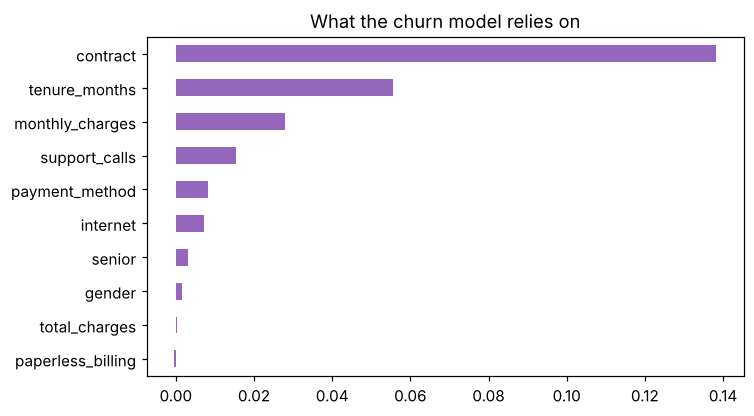

In [10]:
preprocess = ColumnTransformer([
    ("num", make_pipeline(SimpleImputer(strategy="median"), StandardScaler()), make_column_selector(dtype_include="number")),
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="None"), OneHotEncoder(handle_unknown="ignore")), make_column_selector(dtype_include=["object", "string"])),
    ("bool", "passthrough", make_column_selector(dtype_include="bool")),
])
model = Pipeline([("prep", preprocess), ("model", LogisticRegression(C=1, max_iter=1000))]).fit(X_dev, y_dev)
proba = model.predict_proba(X_test)[:, 1]
pred = (proba >= 0.3).astype(int)
print("AUC", round(roc_auc_score(y_test, proba), 3), "recall", round(recall_score(y_test, pred), 2), "precision", round(precision_score(y_test, pred), 2))
print(confusion_matrix(y_test, pred))
r = permutation_importance(model, X_test, y_test, n_repeats=10, random_state=0, scoring="roc_auc")
pd.Series(r.importances_mean, index=X_test.columns).sort_values().plot.barh(color="tab:purple")
plt.title("What the churn model relies on")
plt.show()

## Part D: Cumulative Project: Customer Churn

### Exercise 6: Milestone 6: Model Card, Recommendation and Submission

In [11]:
card = '''
Model card: customer churn
Purpose: rank customers by their risk of leaving, to plan retention calls.
Data: 2,000 practice customers, 10 input columns, 30 percent churn.
Model: logistic regression with imputation, scaling and one-hot encoding in one pipeline.
Performance (test set, used once): AUC 0.80; at threshold 0.3 recall 0.78 and precision 0.53.
Main drivers: month-to-month contract, short tenure, high monthly charges, many support calls.
Limits: practice data; associations, not causes; check and retrain every few months.

Recommendation
Call customers with a risk of 0.3 or more: this finds about 4 in 5 future leavers,
and about every second call reaches a customer who would really leave.
Prioritise new customers on monthly contracts with high bills, and offer them a move to a yearly contract.
Review customers with repeated support calls quickly, since each call raises the risk.
'''
print(card)


Model card: customer churn
Purpose: rank customers by their risk of leaving, to plan retention calls.
Data: 2,000 practice customers, 10 input columns, 30 percent churn.
Model: logistic regression with imputation, scaling and one-hot encoding in one pipeline.
Performance (test set, used once): AUC 0.80; at threshold 0.3 recall 0.78 and precision 0.53.
Main drivers: month-to-month contract, short tenure, high monthly charges, many support calls.
Limits: practice data; associations, not causes; check and retrain every few months.

Recommendation
Call customers with a risk of 0.3 or more: this finds about 4 in 5 future leavers,
and about every second call reaches a customer who would really leave.
Prioritise new customers on monthly contracts with high bills, and offer them a move to a yearly contract.
Review customers with repeated support calls quickly, since each call raises the risk.



## Part E: Quiz Answers

| Question | Answer | Explanation |
| --- | --- | --- |
| 1 | B | Everything else uses cross-validation. |
| 2 | B | Out-of-fold predictions. |
| 3 | B | The two estimates agree. |
| 4 | B | It is a one-page summary for users. |
| 5 | B | Translate metrics into the decision. |